# imports

In [1]:
import sys
import os
import json
import numpy as np
import scipy as sp
import pandas as pd

import importlib

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils

from utils import ai_slob

In [26]:
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)

importlib.reload(ai_slob)

<module 'utils.ai_slob' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/ai_slob.py'>

In [3]:
# specific

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils
sys.path.append(os.path.join(os.getcwd(), '../../../worm-control/src'))
from utils_worm_control import read_utils as read_utils_control

In [4]:
importlib.reload(read_utils)
importlib.reload(read_utils_control)

<module 'utils_worm_control.read_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/worm-2025-fieseler/notebooks/analysis/../../../worm-control/src/utils_worm_control/read_utils.py'>

# setup

In [5]:
ll = 'll00'
data_variant = 'gcamp'

save = True

In [6]:
# specific

model_variant = 'ns'
organism = 'worm'
manual = False
full = False

In [7]:
file_ids = list(range(0, 33+1))
# file_ids = [19, 20, 21]

# load

In [8]:
state_key, state_label = analysis_utils.get_plot_class(organism)
model_path = read_utils.get_model_path()

filenames = analysis_utils.read_filenames(organism, file_ids)
metadata = (filenames, model_path, model_variant, data_variant, manual, full)

# scores

In [9]:
((boms_spn, _, _, _, _, _, _),
 (hgms_spn, _, _, _, _, _, _)) = analysis_utils.read_predictionss(*metadata)

neuron_scores = analysis_utils.assemble_scoress(boms_spn, hgms_spn)

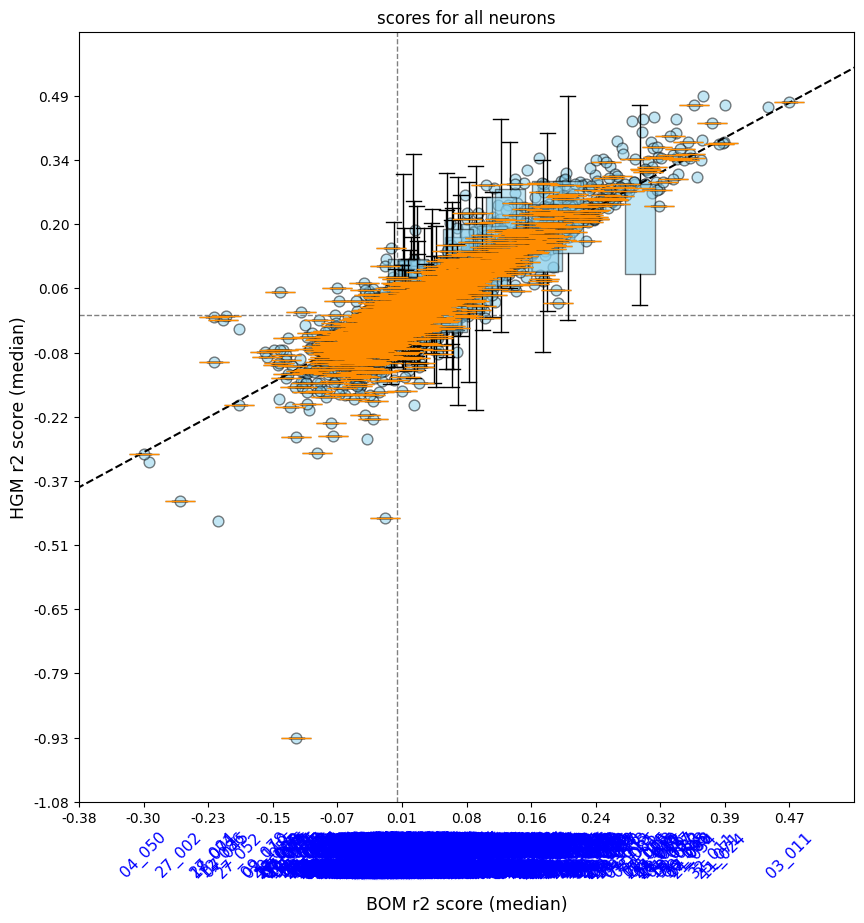

In [10]:
plot_utils.plot_performance_plot(
	neuron_scores, None,
	title='scores for all neurons', limits=None, force_medians=True, horizontal_bps=False,
	# save_path=f'../../out/plots/scores/gfp_control/{model_variant}_scores_all' if save else None,
	save_path=None
)

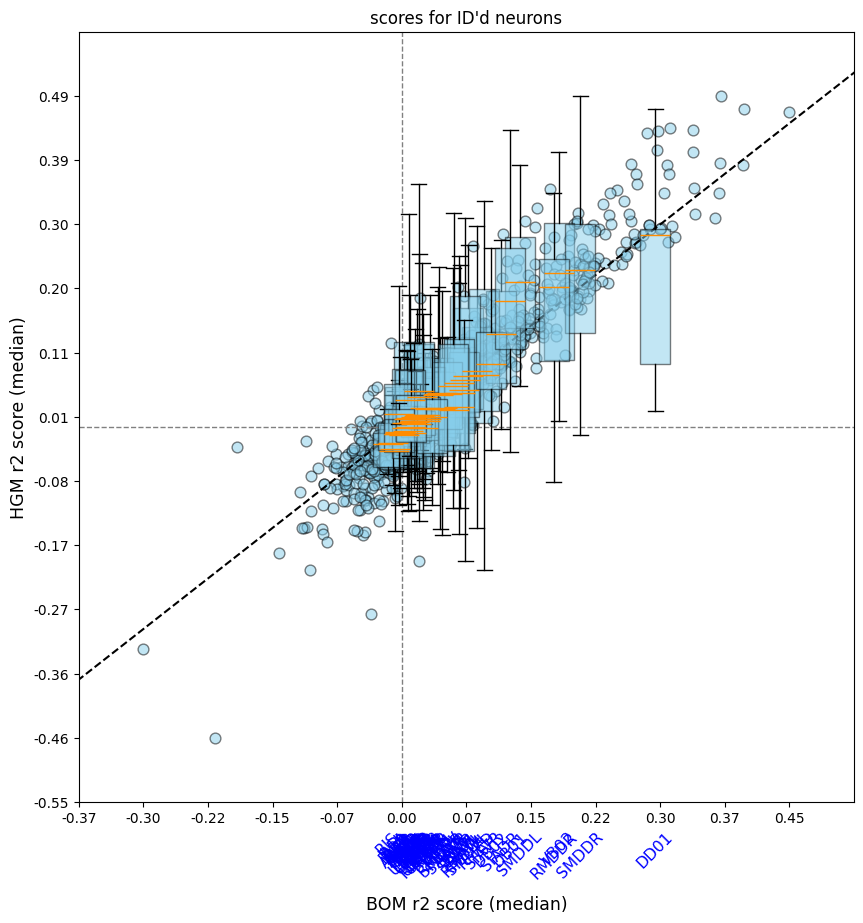

In [11]:
plot_utils.plot_performance_plot(
	{key: neuron_scores[key] for key in neuron_scores.keys() if not key[0].isdigit()}, None,
	title='scores for ID\'d neurons', limits=None, force_medians=False, horizontal_bps=False,
	save_path=f'../../out/plots/scores/gfp_control/{model_variant}_scores_id' if save else None
)

# GFP control

In [12]:
file_ids_gfp = range(0, 7+1)
# file_ids_gfp = [2, 3, 4]

filenames_gfp = analysis_utils.read_filenames(organism, file_ids_gfp, data_variant='gfp')
metadata_gfp = (filenames_gfp, model_path, model_variant, 'gfp', manual, full)

((boms_spn_gfp, _, _, _, _, _, _),
 (hgms_spn_gfp, _, _, _, _, _, _)) = analysis_utils.read_predictionss(*metadata_gfp)

neuron_scores_gfp = analysis_utils.assemble_scoress(boms_spn_gfp, hgms_spn_gfp)

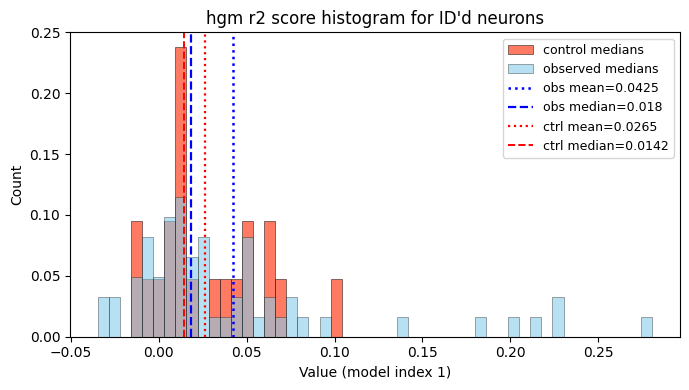

(<Figure size 700x400 with 1 Axes>,
 <Axes: title={'center': "hgm r2 score histogram for ID'd neurons"}, xlabel='Value (model index 1)', ylabel='Count'>)

In [27]:
ai_slob.plot_performance_histogram({key: neuron_scores[key] for key in neuron_scores if not key[0].isdigit()},
								   {key: neuron_scores_gfp[key] for key in neuron_scores_gfp if not key[0].isdigit()},
								   title='hgm r2 score histogram for ID\'d neurons',
								   save_path=f'../../out/plots/scores/gfp_control/{model_variant}_scores_hist_id' if save else None
								   )

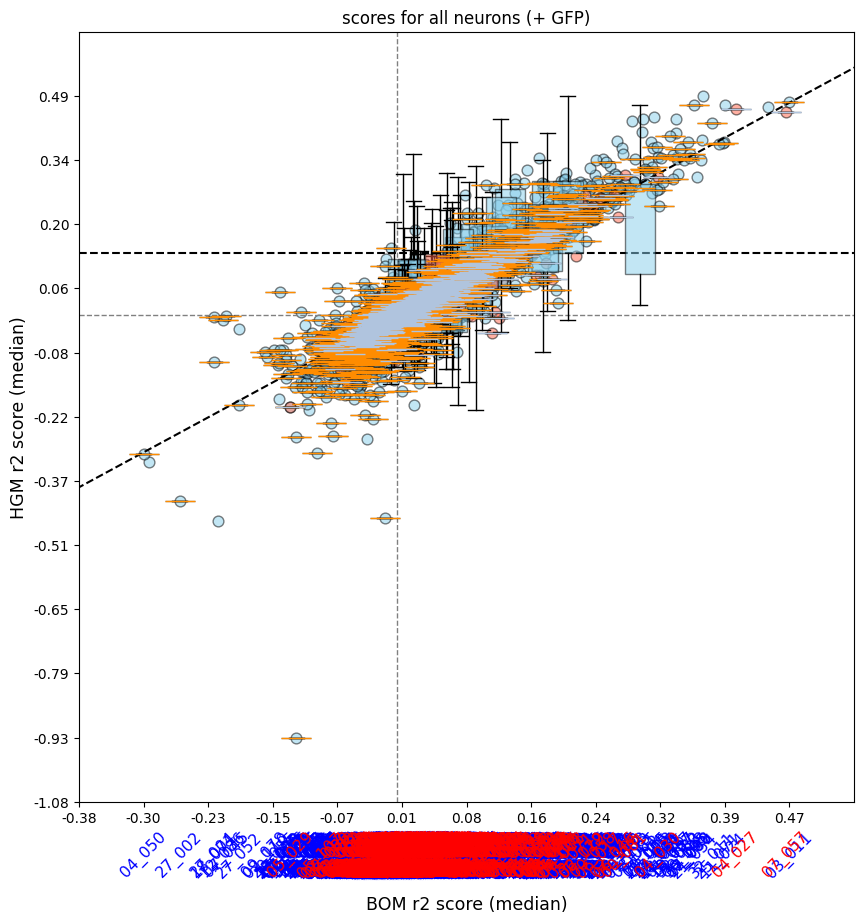

In [14]:
plot_utils.plot_performance_plot(
	neuron_scores, neuron_scores_gfp,
	title='scores for all neurons (+ GFP)', limits=None, force_medians=True, control_cutoff=False, horizontal_bps=False,
	# save_path=f'../../out/plots/scores/gfp_control/{model_variant}_scores_all_gfp' if save else None,
	save_path=None
)

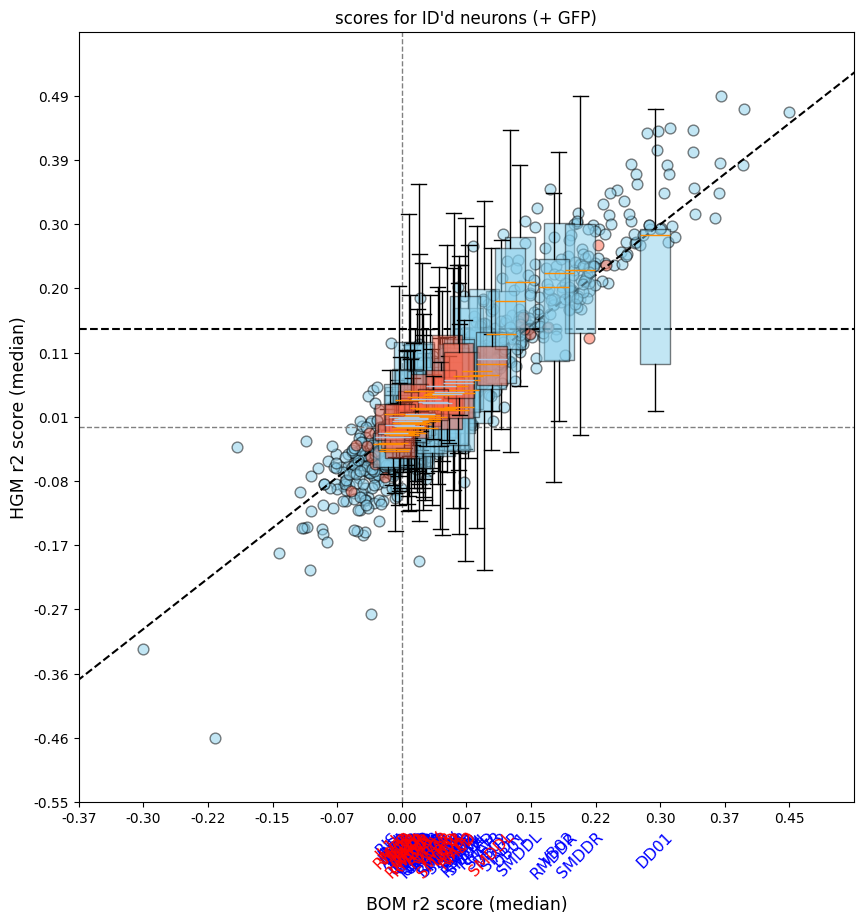

In [15]:
plot_utils.plot_performance_plot(
	{key: neuron_scores[key] for key in neuron_scores.keys() if not key[0].isdigit()},
	{key: neuron_scores_gfp[key] for key in neuron_scores_gfp.keys() if not key[0].isdigit()},
	title='scores for ID\'d neurons (+ GFP)', limits=None, force_medians=False, control_cutoff=False, horizontal_bps=False,
	save_path=f'../../out/plots/scores/gfp_control/{model_variant}_scores_id_gfp' if save else None
)

In [16]:
threshold_hgm_gfp = np.quantile(np.concatenate([pair[1] for pair in neuron_scores_gfp.values()]), 0.95)
threshold_bom_gfp = np.quantile(np.concatenate([pair[0] for pair in neuron_scores_gfp.values()]), 0.95)
threshold_bom_gfp = np.array(0)

neuron_scores_hgm_sig = list(reversed(sorted({key: value for key, value in neuron_scores.items() if np.median(value[1].reshape(-1, 1)) > threshold_hgm_gfp and np.median(value[0].reshape(-1, 1)) > threshold_bom_gfp}.items(), key=lambda x: np.median(x[1][1]))))
neuron_scores_hgm_sig_labels = list([val[0] for val in neuron_scores_hgm_sig])

print('\n'.join([f'NEURON: {key},\t\tHGMSCR: {np.median(val[1]):.4f}' for key, val in neuron_scores_hgm_sig if not key[0].isdigit()]))

NEURON: DD01,		HGMSCR: 0.2808
NEURON: SMDDR,		HGMSCR: 0.2302
NEURON: VB02,		HGMSCR: 0.2258
NEURON: SMDDL,		HGMSCR: 0.2120
NEURON: RMDDR,		HGMSCR: 0.2045
NEURON: DB01,		HGMSCR: 0.1844


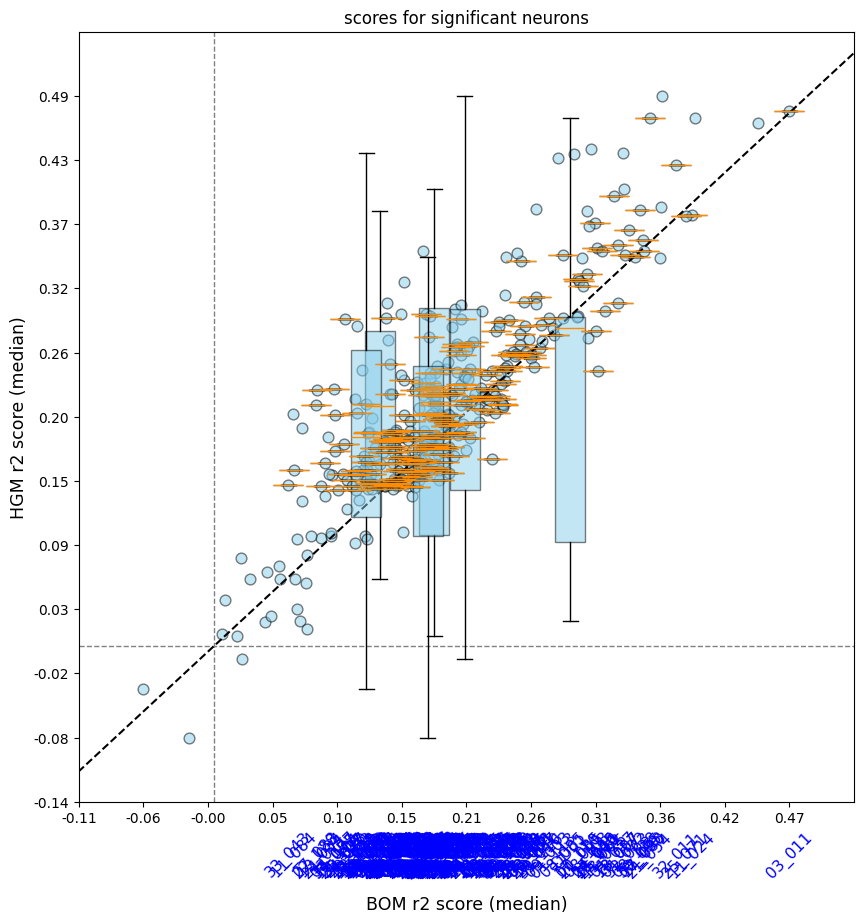

In [17]:
plot_utils.plot_performance_plot(
	{key: neuron_scores[key] for key in neuron_scores_hgm_sig_labels}, None,
	title='scores for significant neurons', limits=None, force_medians=True, horizontal_bps=False,
	# save_path=f'../../out/plots/scores/gfp_control/{model_variant}_scores_significant' if save else None,
	save_path=None
)

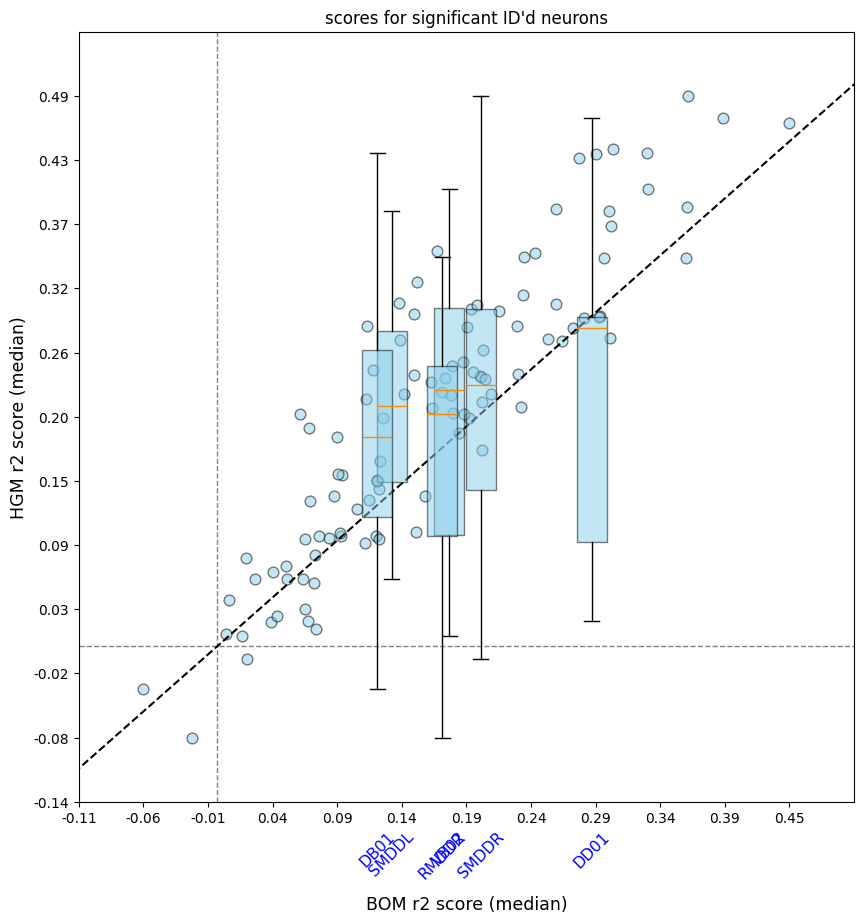

In [18]:
plot_utils.plot_performance_plot(
	{key: neuron_scores[key] for key in neuron_scores_hgm_sig_labels if not key[0].isdigit()}, None,
	title='scores for significant ID\'d neurons', limits=None, force_medians=False, horizontal_bps=False,
	save_path=f'../../out/plots/scores/gfp_control/{model_variant}_scores_id_significant' if save else None
)

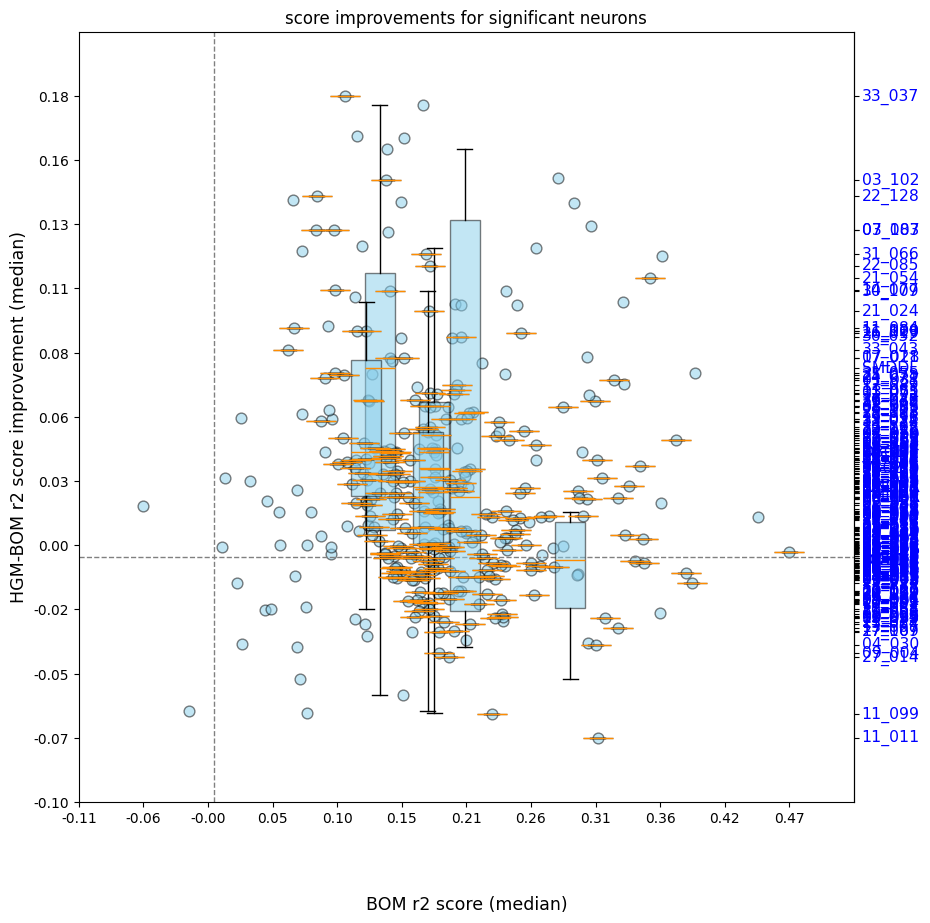

In [19]:
plot_utils.plot_improvement_plot(
	{key: neuron_scores[key] for key in neuron_scores_hgm_sig_labels},
	title='score improvements for significant neurons', limits=None, force_medians=True, horizontal_bps=False,
	# save_path=f'../../out/plots/scores/gfp_control/{model_variant}_impros_significant' if save else None,
	save_path=None
)

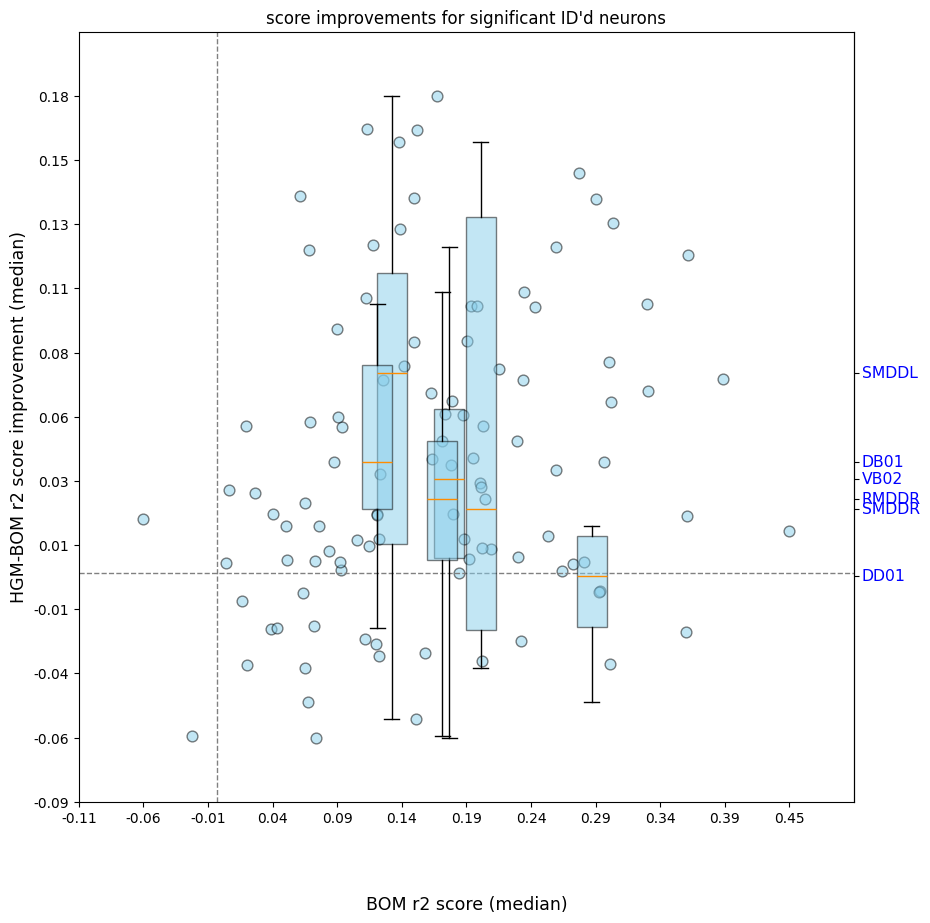

In [20]:
plot_utils.plot_improvement_plot(
	{key: neuron_scores[key] for key in neuron_scores_hgm_sig_labels if not key[0].isdigit()}, None,
	title='score improvements for significant ID\'d neurons', limits=None, force_medians=False, horizontal_bps=False,
	save_path=f'../../out/plots/scores/gfp_control/{model_variant}_impros_id_significant' if save else None
)

In [21]:
neuron_impros_hgm_sig = list(reversed(sorted(neuron_scores_hgm_sig, key=lambda x: np.median(x[1][1] - x[1][0]))))
neuron_impros_hgm_rel_labels = list([val[0] for val in neuron_impros_hgm_sig])

print('\n'.join([f'NEURON: {key},\t\tIMPR: {np.median(val[1] - val[0]):.4f}' for key, val in neuron_impros_hgm_sig if not key[0].isdigit()]))

NEURON: SMDDL,		IMPR: 0.0746
NEURON: DB01,		IMPR: 0.0416
NEURON: VB02,		IMPR: 0.0352
NEURON: RMDDR,		IMPR: 0.0277
NEURON: SMDDR,		IMPR: 0.0238
NEURON: DD01,		IMPR: -0.0011


In [22]:
print('Neuron names for copying:')
print(', '.join([f'\'{label}\'' for label in neuron_impros_hgm_rel_labels if not label[0].isdigit()]))

Neuron names for copying:
'SMDDL', 'DB01', 'VB02', 'RMDDR', 'SMDDR', 'DD01'
